深度学习是机器学习的一类方法，核心是使用多层神经网络学习数据规律。

MLP 是 Multi-Layer Perceptron（多层感知机），最基础的前馈神经网络。

| PyTorch 工具 | 作用              |
| ---------- | --------------- |
| Tensor     | 保存模型输入、输出、参数和梯度 |
| `torch.nn` | 创建神经网络层和损失函数    |
| 自动求导       | 自动计算模型参数的梯度     |
| 优化器        | 根据梯度更新权重和偏置     |
| CPU/GPU 支持 | 在不同计算设备上运行模型    |

PyTorch 是深度学习框架：提供张量（Tensor）做数值计算，提供自动求导（Autograd）算梯度，让你能训练神经网络。

## 二、人工神经元与网络结构


人工神经元是神经网络中最基本的计算单元。它受到生物神经元处理信息方式的启发，但本质上是一个数学计算模型：接收多个输入，经过计算后产生一个输出。许多人工神经元连接在一起，就组成了神经网络。

### 2.2 输入层、隐藏层和输出层

| 层级  | 主要作用                      |
| --- | ------------------------- |
| 输入层 | 接收特征，并将数据传给后续网络           |
| 隐藏层 | 对输入进行加权组合和非线性转换，学习有用的中间特征 |
| 输出层 | 将隐藏层结果转换成任务需要的预测形式        |

### 2.3 参数量计算

```plain
Linear(输入数量, 输出数量)
参数量 = 输入数量 × 输出数量 + 输出数量
```

| 网络层            |         权重数量 | 偏置数量 | 参数总数 |
| -------------- | -----------: | ---: | ---: |
| `Linear(4, 6)` | `4 × 6 = 24` |  `6` | `30` |
| `Linear(6, 3)` | `6 × 3 = 18` |  `3` | `21` |
| 合计             |         `42` |  `9` | `51` |

## 三、神经网络如何学习

 **预测 → 对照答案 → 计算误差 → 找到调整方向 → 微调参数 → 重复。**

### 3.1 前向传播：让网络先作答

**前向传播（Forward Propagation）**是指数据从输入层向输出层流动，依次经过各层计算并产生预测结果的过程。

### 3.2 损失函数：给这次作答打分

> **损失（Loss）**：衡量模型预测结果与真实答案之间差距的数值。
> **训练目标**：让损失尽可能小。

拿到预测结果后，损失函数会把它与真实标签进行比较，并给出一个表示错误程度的数值。损失越小，通常表示预测越接近真实答案。

### 3.4 重复纠错：Batch、Iteration 和 Epoch

- Batch：一次送入模型的一小批样本；
- Iteration：处理一个 Batch 并更新一次参数；
- Epoch：完整学习一遍训练集。

每个 Epoch 包含的 Iteration 数量可以这样计算：

```plain
Iteration 数量 = 训练集样本数 ÷ Batch Size
不能整除时向上取整
```

### 3.5 用 PyTorch 完成一次参数更新

模型处理一个 Batch 并完成一次参数更新，就是一次 Iteration。它对应前面介绍的完整纠错流程：

- 前向传播：数据从输入层经过网络，得到预测结果；
- 计算损失：把预测结果与真实标签进行比较；
- 反向传播：根据损失计算每个参数的梯度；
- 优化器更新：根据梯度和学习率修改权重、偏置。

| 代码                                     | 作用           |
| -------------------------------------- | ------------ |
| `optimizer.zero_grad()`                | 清除上一轮累积的梯度   |
| `logits = model(features)`             | 前向计算预测分数     |
| `loss = loss_function(logits, labels)` | 计算预测损失       |
| `loss.backward()`                      | 计算损失相对各参数的梯度 |
| `optimizer.step()`                     | 根据梯度更新参数     |

`loss.backward()`只负责计算梯度，真正修改权重和偏置的是`optimizer.step()`。

PyTorch 默认会累积梯度，因此开始处理每个 Batch 时，都要使用`optimizer.zero_grad()`清除上一轮梯度。

## 四、Tensor 基础

### 4.2 创建 Tensor

| 创建方式             | 作用                      |
| ---------------- | ----------------------- |
| `torch.tensor()` | 根据已有 Python 数据创建 Tensor |
| `torch.zeros()`  | 创建元素全为 0 的 Tensor       |
| `torch.ones()`   | 创建元素全为 1 的 Tensor       |
| `torch.rand()`   | 创建元素为 `0～1` 随机数的 Tensor |

In [3]:
import torch

In [4]:
print('PyTorch 版本: ', torch.__version__)

PyTorch 版本:  2.14.1+cpu


In [9]:
#根据已有的Python数据创建Tensor
tensor_features = torch.tensor([
    [0.2, 0.5, 0.8],
    [0.1, 0.9, 0.4],
], dtype=torch.float32)

In [10]:
#多分类标签使用整数类别编号
tensor_labels = torch.tensor(
    [1, 0],
    dtype=torch.long
)

In [11]:
print(tensor_features)
print(tensor_labels)
print(torch.zeros((2, 3)))
print(torch.ones((2, 3)))
print(torch.rand((2, 3)))

tensor([[0.2000, 0.5000, 0.8000],
        [0.1000, 0.9000, 0.4000]])
tensor([1, 0])
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0.3519, 0.3978, 0.0032],
        [0.4352, 0.9528, 0.1232]])


Tensor 中的元素使用统一的数据类型。模型输入通常使用浮点类型，多分类标签通常使用整数类型 torch.long。

### 4.4 索引、切片和基础运算

In [12]:
# 索引：取出第 1 个样本
print("第 1 个样本：", tensor_features[0])

# 切片：取出所有样本的第 2 个特征
print("第 2 个特征：", tensor_features[:, 1])

# 基础运算：每个元素乘以 2
print("特征乘以 2：", tensor_features * 2)

# dim=0：对每一列求平均值，得到每个特征的均值
column_means = tensor_features.mean(dim=0)
print("每列均值：", column_means)

# item() 将只包含一个元素的 Tensor 转换成 Python 数值
overall_mean = tensor_features.mean().item()
print("全部特征的均值：", overall_mean)

第 1 个样本： tensor([0.2000, 0.5000, 0.8000])
第 2 个特征： tensor([0.5000, 0.9000])
特征乘以 2： tensor([[0.4000, 1.0000, 1.6000],
        [0.2000, 1.8000, 0.8000]])
每列均值： tensor([0.1500, 0.7000, 0.6000])
全部特征的均值： 0.4833333194255829


### 4.5 NumPy 与 Tensor 转换

In [13]:
import numpy as np
import torch

In [14]:
numpy_features = np.array([
    [0.2, 0.5, 0.8],
    [0.1, 0.9, 0.4],
], dtype=np.float32)

In [15]:
# NumPy 数组转换为 Tensor
tensor_from_numpy = torch.from_numpy(
    numpy_features
)

In [16]:
# CPU Tensor 转换回 NumPy 数组
numpy_from_tensor = tensor_from_numpy.numpy()

In [17]:
print(type(numpy_features))
print(type(tensor_from_numpy))
print(type(numpy_from_tensor))

<class 'numpy.ndarray'>
<class 'torch.Tensor'>
<class 'numpy.ndarray'>


## 五、Dataset 与 DataLoader

| 工具              | 作用                                         |
| --------------- | ------------------------------------------ |
| `Dataset`       | 表示一个完整数据集，并规定如何获取某一条样本                     |
| `TensorDataset` | PyTorch 提供的现成 Dataset，按照第 0 维把多个 Tensor 配对 |
| `DataLoader`    | 从 Dataset 中分批取出数据，并提供打乱和迭代能力               |

Dataset 回答“第 i 条样本是什么”，DataLoader 回答“怎么把样本组成 batch 送进模型”。

In [18]:
import torch
from torch.utils.data import DataLoader, TensorDataset

In [19]:
# 4 条样本，每条样本包含 3 个特征
loader_features = torch.tensor([
    [0.2, 0.5, 0.8],
    [0.1, 0.9, 0.4],
    [0.6, 0.3, 0.7],
    [0.8, 0.2, 0.5],
], dtype=torch.float32)

In [20]:
# 4 条样本对应的分类标签
loader_labels = torch.tensor(
    [1, 0, 1, 0],
    dtype=torch.long
)

In [23]:
# 按照第 0 维，将每一行特征与同位置的标签配对
tensor_dataset = TensorDataset(
    loader_features,
    loader_labels
)
print(tensor_dataset)

In [24]:
# 把 TensorDataset 包装成按批次（batch）迭代的数据加载器。
tensor_loader = DataLoader(
    tensor_dataset,
    # 每个 Batch 读取 2 条样本
    batch_size=2,
    # 本示例不打乱，方便观察分批结果
    shuffle=False
)

In [25]:
for batch_number, (batch_features, batch_labels) in enumerate(tensor_loader, start=1):
    print(f"第 {batch_number} 个 Batch")
    print("特征形状：", batch_features.shape)
    print("标签形状：", batch_labels.shape)
    print("特征：", batch_features)
    print("标签：", batch_labels)

第 1 个 Batch
特征形状： torch.Size([2, 3])
标签形状： torch.Size([2])
特征： tensor([[0.2000, 0.5000, 0.8000],
        [0.1000, 0.9000, 0.4000]])
标签： tensor([1, 0])
第 2 个 Batch
特征形状： torch.Size([2, 3])
标签形状： torch.Size([2])
特征： tensor([[0.6000, 0.3000, 0.7000],
        [0.8000, 0.2000, 0.5000]])
标签： tensor([1, 0])


`loader_features` 和 `loader_labels` 的第 0 维都必须是 `4`，这样每条样本才能找到对应标签。每次循环会得到一个 Batch：特征形状为 `(2, 3)`，标签形状为 `(2,)`。

完整遍历一次 `DataLoader` 相当于完成一个 Epoch；每取出并训练一个 Batch，相当于完成一次 Iteration。

训练集通常使用 `shuffle=True`，减少固定样本顺序带来的影响；验证集和测试集通常使用 `shuffle=False`。

## 六、PyTorch 基础流程

### 6.1 PyTorch 完整流程概览

| 步骤      | 主要工作                                   |
| ------- | -------------------------------------- |
| 1. 准备数据 | 整理特征和标签，并转换成 Tensor                    |
| 2. 分批读取 | 使用 Dataset 组织数据，使用 DataLoader 生成 Batch |
| 3. 定义模型 | 使用 `nn.Sequential` 等方式搭建神经网络           |
| 4. 配置训练 | 定义损失函数和优化器                             |
| 5. 训练模型 | 前向传播、计算损失、反向传播、更新参数                    |
| 6. 评估预测 | 切换到评估模式，关闭梯度并输出预测结果                    |

In [28]:
# 这是一段流程骨架，不能直接运行
# 省略号表示此处需要替换成真实的数据或对象

# 1. 准备 DataLoader
# train_loader：分批读取训练特征和训练标签
train_loader = ...
# test_loader：分批读取测试特征和测试标签
test_loader = ...

# 2. 定义模型、损失函数和优化器
# model：具体的神经网络结构
model = ...
# loss_function：衡量预测结果与真实标签之间的差距
loss_function = ...
# optimizer：根据梯度更新模型参数
optimizer = ...

In [30]:
# 3. 训练模型
# 外层循环：完整遍历训练集 10 次，也就是训练 10 个 Epoch
for epoch in range(10):
    # 将模型切换到训练模式
    model.train()

    # 内层循环：每次从训练集中取出一个 Batch
    for features, labels in train_loader:
        # 清空上一个 Batch 留下的梯度
        optimizer.zero_grad()

        #前向传播：输入特征，得到模型预测的 Logit
        logits = model(features)

        # 计算当前 Batch 的预测损失
        loss = loss_function(logits, labels)

        #反向传播：计算损失相对各参数的梯度
        loss.backward()

        # 根据梯度和学习率更新权重、偏置
        optimizer.step()

# 4. 评估或预测
# 将模型切换到评估模式
model.eval()

# 评估时关闭梯度记录，不更新模型参数
with torch.no_grad():
    # 分批读取测试数据
    for features, labels in test_loader:
        #前向传播，得到每条数据的类别分数
        logits = model(features)

        # dim=1：在每一行的类别分数中找出最大值位置
        # 最大值所在的位置就是预测类别
        predictions = logits.argmax(dim=1)

AttributeError: 'ellipsis' object has no attribute 'train'

这套流程可以概括为：

```text
数据 → 模型 → 训练 → 评估 → 预测
```

| 代码                | 作用                 |
| ----------------- | ------------------ |
| `model.train()`   | 将模型切换到训练模式         |
| `model.eval()`    | 将模型切换到评估模式         |
| `torch.no_grad()` | 关闭梯度记录，减少无用计算和内存占用 |

## 七、了解手写数字识别流程

### 7.1 加载并观察数据

In [31]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

In [32]:
# 加载 scikit-learn 内置的手写数字数据集
digits = load_digits()

In [44]:
# digits.data：每行是一张图片，共有 64 个像素特征
# astype("float32")：转换为神经网络常用的浮点类型
# 除以 16.0：load_digit的像素值范围是 0～16, 缩放到 0～1
digit_features = digits.data.astype('float32') / 16.0

# digits.target：每张图片对应的真实数字 0～9
# int64 可以转换成 PyTorch 多分类需要的 long 类型
digit_labels = digits.target.astype('int64')
print('特征形状: ', digit_features)
print('标签形状: ', digit_labels)

特征形状:  [[0.     0.     0.3125 ... 0.     0.     0.    ]
 [0.     0.     0.     ... 0.625  0.     0.    ]
 [0.     0.     0.     ... 1.     0.5625 0.    ]
 ...
 [0.     0.     0.0625 ... 0.375  0.     0.    ]
 [0.     0.     0.125  ... 0.75   0.     0.    ]
 [0.     0.     0.625  ... 0.75   0.0625 0.    ]]
标签形状:  [0 1 2 ... 8 9 8]


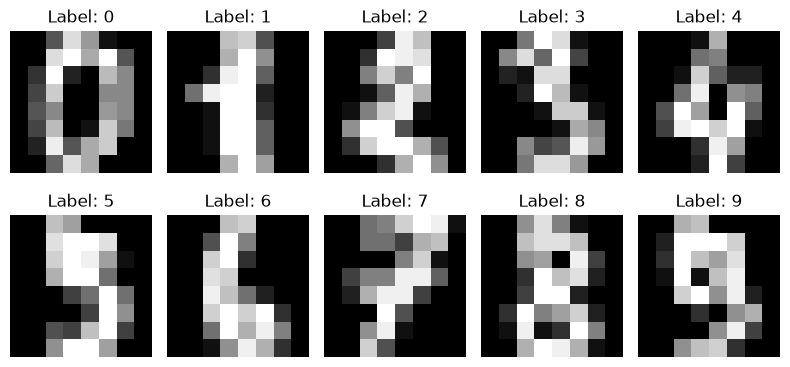

In [45]:
# 创建 2 行 5 列的画布，准备显示前 10 张图片
figure, axes = plt.subplots(2, 5, figsize=(8, 4))

# axes.ravel() 将二维子图展开，方便依次处理
for index, axis in enumerate(axes.ravel()):
    axis.imshow(
        # digits.images 中的每张图片形状都是 8 × 8
        digits.images[index],
        # 使用灰度颜色显示图片
        cmap='gray',
    )
    # 在图片上方显示真实标签
    axis.set_title(f'Label: {digit_labels[index]}')
    # 隐藏坐标轴
    axis.axis('off')

# 自动调整子图间距，避免标题重叠
plt.tight_layout()
plt.show()

### 7.2 划分数据并创建 DataLoader

In [46]:
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

In [47]:
# 80% 用于训练，20% 用于最终测试
features_train, features_test, labels_train, labels_test = (
    train_test_split(
        # 要划分的特征和标签
        digit_features,
        digit_labels,
        #20% 作为测试集，剩余 80% 作为训练集
        test_size=0.2,
        # 固定随机种子，保证每次划分结果一致
        random_state=42,
        # 保持训练集和测试集的类别比例接近
        stratify=digit_labels,
    )
)

In [49]:
# TensorDataset 将每行训练特征与同位置的标签配对, torch.tensor 和 np.array 有点类似
train_dataset = TensorDataset(
    #模型输入使用 float32 类型
    torch.tensor(features_train, dtype=torch.float32),
    # 多分类标签使用 long 类型
    torch.tensor(labels_train, dtype=torch.long)
)

In [50]:
# 测试数据也按照相同方式转换并配对
test_dataset = TensorDataset(
    torch.tensor(features_test, dtype=torch.float32),
    torch.tensor(labels_test, dtype=torch.long)
)

In [51]:
train_loader = DataLoader(
    # 从训练数据集中分批读取数据
    train_dataset,
    # 每次读取 64 条训练数据
    batch_size=64,
    # 每个 Epoch 打乱训练数据顺序
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    # 测试时不需要打乱数据
    shuffle=False
)

print('训练集样本数: ', len(train_dataset))
print('测试集样本数: ', len(test_dataset))

训练集样本数:  1437
测试集样本数:  360


### 7.3 搭建并训练模型

In [52]:
from torch import nn

In [53]:
# 固定 PyTorch 随机种子，使模型初始化结果可复现
torch.manual_seed(42)

In [54]:
# Sequential 表示数据按照下面的顺序通过各层
model = nn.Sequential(
    # 输入 64 个像素特征，隐藏层包含 64 个神经元
    nn.Linear(64, 64),
    # 对隐藏层结果进行非线性转换
    nn.ReLU(),
    # 输出 10 个 Logit，分别对应数字 0～9
    nn.Linear(64, 10),
)

In [58]:
# 多分类任务使用交叉熵损失函数
loss_function = nn.CrossEntropyLoss()

In [59]:
# Adam 优化器负责更新模型中的权重和偏置
optimizer = torch.optim.Adam(
    # 指定需要更新的全部模型参数
    model.parameters(),
    # 学习率决定每次更新参数的步幅
    lr=0.001,
)

In [60]:
# range(1, 11) 表示训练 10 个 Epoch
for epoch in range(1, 11):
    # 将模型切换到训练模式
    model.train()
    # 记录当前 Epoch 中各 Batch 的损失之和
    total_loss = 0.0

    # 每次从 DataLoader 中取出一个 Batch
    for batch_features, batch_labels in train_loader:
        # 清空上一批数据留下的梯度
        optimizer.zero_grad()

        # 前向传播，得到 10 个类别的分数
        logits = model(batch_features)

        # 计算预测结果与真实标签之间的损失
        loss = loss_function(logits, batch_labels)

        # 反向传播，计算每个参数的梯度
        loss.backward()
        # 根据梯度和学习率更新参数
        optimizer.step()

        # item() 将单个 Tensor 损失转换成 Python 数值
        total_loss += loss.item()

    # len(train_loader) 是当前 Epoch 的 Batch 数量
    average_loss = total_loss / len(train_loader)
    print(
        f"Epoch {epoch:02d}，"
        f"平均损失：{average_loss:.4f}"
    )

Epoch 01，平均损失：2.2379
Epoch 02，平均损失：2.0522
Epoch 03，平均损失：1.7971
Epoch 04，平均损失：1.4950
Epoch 05，平均损失：1.2015
Epoch 06，平均损失：0.9554
Epoch 07，平均损失：0.7775
Epoch 08，平均损失：0.6456
Epoch 09，平均损失：0.5506
Epoch 10，平均损失：0.4791


训练过程中，损失整体下降，表示模型的预测正在逐渐接近真实答案。

### 7.4 测试模型并查看预测结果

In [61]:
# 将模型切换到评估模式
model.eval()

Sequential(
  (0): Linear(in_features=64, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=10, bias=True)
)

In [62]:
# 记录预测正确数量和测试样本总数
correct_count = 0
sample_count = 0

In [63]:
# 测试过程不需要计算梯度
with torch.no_grad():
    #分批读取测试数据
    for batch_features, batch_labels in test_loader:
        # 前向传播，得到每张图片的 10 个 Logit
        logits = model(batch_features)
        # dim=1：在每一行的 10 个类别分数中寻找最大值位置
        predictions = logits.argmax(dim=1)

        # 比较预测标签和真实标签，并累计预测正确数量
        correct_count += (
            predictions == batch_labels
        ).sum().item()
        # 累计已经测试的样本数量
        sample_count += len(batch_labels)


In [65]:
# Accuracy = 预测正确数量 ÷ 测试样本总数
test_accuracy = correct_count / sample_count
print(f'测试集 Accuracy：{test_accuracy:.3f}')

测试集 Accuracy：0.919


In [66]:
# 预测测试集中的前 10 张图片

#把测试集前 10 条特征转成 PyTorch 张量，并指定 float32 类型
example_features = torch.tensor(
    # [:10] 表示取前 10 行特征
    features_test[:10],
    # 模型输入必须使用 float32 类型
    dtype=torch.float32,
)

In [67]:
# 测试过程不需要计算梯度
with torch.no_grad():
    example_predictions = (
        # 得到前 10 张图片的类别分数
        model(example_features)
        # 取每张图片分数最高的类别
        .argmax(dim=1)
        # 转换成 NumPy 数组，方便后续显示
        .numpy()
    )

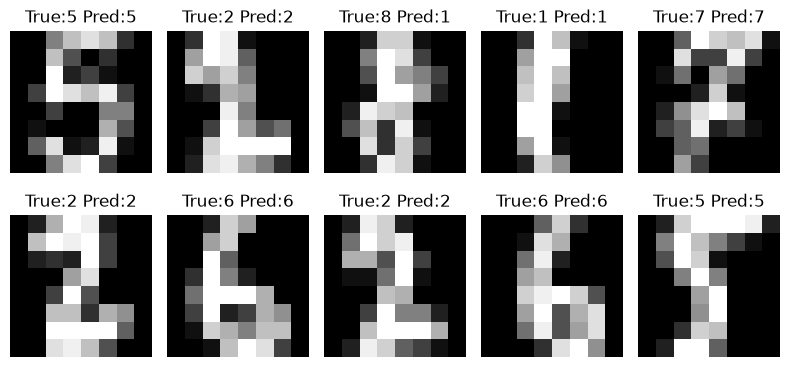

In [72]:
# 创建 2 行 5 列的画布
#axes 是 2×5 的 ndarray，每个元素是一个子图
figure, axes = plt.subplots(2, 5, figsize=(8, 4))
#axes.reval()把2*5的ndarray展平成10个元素的数组
for index, axis in enumerate(axes.ravel()):
    axis.imshow(
        # 将 64 个像素恢复成 8 × 8 图片
        features_test[index].reshape(8, 8),
        cmap="gray",
    )
    # True 是真实标签，Pred 是模型预测标签
    axis.set_title(
        f"True:{labels_test[index]} "
        f"Pred:{example_predictions[index]}"
    )
    #去掉坐标轴
    axis.axis("off")

plt.tight_layout()
plt.show()

```text
加载图片数据
→ 创建 DataLoader
→ 定义神经网络
→ 训练模型
→ 计算测试 Accuracy
→ 查看预测结果
```